# Assignment 06: Agricultural Genomics and Crop Improvement
**Aim:** Identify genetic markers (SNPs) associated with a crop trait using association analysis (GWAS) on **real crop data**.

**Dataset:** Wheat genotypic and phenotypic data (337 hard winter wheat lines, GBS SNPs) - Dryad: https://datadryad.org/dataset/doi:10.5061/dryad.6wwpzgn71
Traits available: SRC-W (water absorption capacity), kernel diameter, kernel hardness, break-flour yield, total flour yield.

**Workflow:** Load data -> QC -> Association test per SNP -> Multiple-testing correction -> Manhattan & QQ plots -> Interpretation

## 1. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

np.random.seed(42)

## 2. Load genomic data
Download and extract the dataset, then set the paths below.
- **Genotype file:** SNP genotypes coded 0/1/2. In the wheat file each **row is a SNP** and each **column is a wheat line**.
- **Phenotype file:** one row per line, with an ID column and trait columns.

In [2]:
# ====== CHANGE ONLY THESE LINES ======
GENO_PATH  = r"Genotypic_data.csv"
PHENO_PATH = r"Phenotypic_data.txt"
TRAIT_COL  = "SRC-W"        # trait column name in the phenotype file
SNPS_AS_ROWS = True         # True: rows = SNPs, columns = lines (wheat file). False: rows = lines
# =====================================

# --- Phenotype (comma / tab separated is detected automatically) ---
pheno_df = pd.read_csv(PHENO_PATH, sep=None, engine="python")
print("Phenotype columns:", list(pheno_df.columns))
pheno_df = pheno_df.set_index(pheno_df.columns[0])          # first column = line ID
pheno_df.index = pheno_df.index.astype(str)
pheno = pd.to_numeric(pheno_df[TRAIT_COL], errors="coerce").dropna()
pheno = pheno.groupby(level=0).mean()                      # average repeated IDs
pheno.name = TRAIT_COL

# --- Genotype ---
raw = pd.read_csv(GENO_PATH, low_memory=False)
raw.columns = raw.columns.astype(str)
raw = raw.set_index(raw.columns[0])
raw.index = raw.index.astype(str)

snp_info = None
if SNPS_AS_ROWS:
    lines = [c for c in raw.columns if c in pheno.index]          # columns that are wheat lines
    meta = raw.drop(columns=lines)                                # other columns (alleles, chrom, pos ...)
    geno = raw[lines].T                                           # rows = lines, columns = SNPs
    lower = {c.lower(): c for c in meta.columns}
    chr_c = next((lower[k] for k in ("chrom", "chr", "chromosome") if k in lower), None)
    pos_c = next((lower[k] for k in ("pos", "position") if k in lower), None)
    if chr_c and pos_c:
        snp_info = pd.DataFrame({"SNP": meta.index, "CHR": meta[chr_c].astype(str).values,
                                 "POS": pd.to_numeric(meta[pos_c], errors="coerce").values})
else:
    geno = raw.loc[raw.index.isin(pheno.index)]

# keep lines present in both files
common = [s for s in geno.index if s in pheno.index]
print("Lines in genotype file:", geno.shape[0], "| lines matched with phenotype:", len(common))
if len(common) < 20:
    raise ValueError("Line IDs do not match between genotype and phenotype files. "
                     "Compare: " + str(list(geno.index[:3])) + " vs " + str(list(pheno.index[:3])))
geno, pheno = geno.loc[common], pheno.loc[common]

# SNP map: if no chromosome/position info, use one chromosome in file order
if snp_info is None:
    print("No chromosome/position columns found - SNPs will be plotted in file order.")
    snp_info = pd.DataFrame({"SNP": geno.columns, "CHR": "1", "POS": np.arange(geno.shape[1])})
snp_info["POS"] = snp_info["POS"].fillna(0)

print("Lines x SNPs:", geno.shape)
geno.iloc[:5, :6]

Phenotype columns: ['ID', 'Hardness', 'Diameter', 'T-Flour', 'B-Flour', 'SRC-W']
Lines in genotype file: 496 | lines matched with phenotype: 496
Lines x SNPs: (496, 23130)


rs#,rs01,rs02,rs03,rs04,rs05,rs06
GID1,C,G,A,A,G,C
GID2,C,G,A,A,R,C
GID3,A,G,A,A,A,C
GID4,C,G,A,A,A,C
GID5,A,G,A,A,A,C


## 3. Quality control
Check the genotype coding, remove SNPs with low minor allele frequency (MAF < 5%) and fill missing values.

In [3]:
print("Example raw genotype values:", geno.iloc[:3, :4].values.tolist())

# Step A: try plain numbers (0/1/2)
num = geno.apply(pd.to_numeric, errors="coerce")
is_text = (num.isna() & geno.notna()).mean().mean() > 0.5

# Step B: if genotypes are text (A/G, AA, 0|1, R/Y/K ...), convert to 0/1/2 = copies of the minor allele
IUPAC = {"R": "AG", "Y": "CT", "S": "CG", "W": "AT", "K": "GT", "M": "AC"}

def to_pair(g):
    g = str(g).replace("|", "").replace("/", "").replace(" ", "").upper()
    if len(g) == 2 and set(g) <= set("ACGT012"):
        return g
    if len(g) == 1 and g in "ACGT":
        return g + g
    if len(g) == 1 and g in IUPAC:
        return IUPAC[g]
    return None                                  # missing (N, ., NA ...)

def text_to_dose(df):
    out = {}
    for snp in df.columns:
        col = df[snp]
        counts = col.value_counts()
        pairs = {u: to_pair(u) for u in counts.index}
        allele_n = {}
        for u, n in counts.items():
            if pairs[u]:
                for a in pairs[u]:
                    allele_n[a] = allele_n.get(a, 0) + n
        minor = min(allele_n, key=allele_n.get) if allele_n else None
        out[snp] = col.map({u: (p.count(minor) if p and minor else np.nan) for u, p in pairs.items()})
    return pd.DataFrame(out, index=df.index)

if is_text:
    print("Genotypes are text - converting to 0/1/2 (this can take a minute) ...")
    geno = text_to_dose(geno)
else:
    geno = num

# genotype must be 0/1/2 (a -1/0/1 coding is converted)
if geno.min().min() == -1:
    geno = geno + 1
if geno.isna().mean().mean() > 0.5 or geno.max().max() > 2:
    raise ValueError("Genotypes could not be converted to 0/1/2. Please send the 'Example raw genotype values' line above.")

print("Missing genotype values:", int(geno.isna().sum().sum()))
geno = geno.fillna(geno.mean())                     # fill missing with SNP mean

dose_max = 2 if geno.max().max() > 1 else 1         # 0/1 coding is used for inbred lines
allele_freq = geno.mean() / dose_max
maf_vals = np.minimum(allele_freq, 1 - allele_freq)

geno = geno.loc[:, maf_vals >= 0.05]
snp_info = snp_info[snp_info["SNP"].isin(geno.columns)].drop_duplicates("SNP").reset_index(drop=True)
geno = geno[snp_info["SNP"]]

print("SNPs after QC:", geno.shape[1])
print(pheno.describe())

Example raw genotype values: [['C', 'G', 'A', 'A'], ['C', 'G', 'A', 'A'], ['A', 'G', 'A', 'A']]
Genotypes are text - converting to 0/1/2 (this can take a minute) ...
Missing genotype values: 219765
SNPs after QC: 22797
count    496.000000
mean      60.566945
std        2.756273
min       54.364503
25%       58.661166
50%       60.071524
75%       62.245855
max       71.153918
Name: SRC-W, dtype: float64


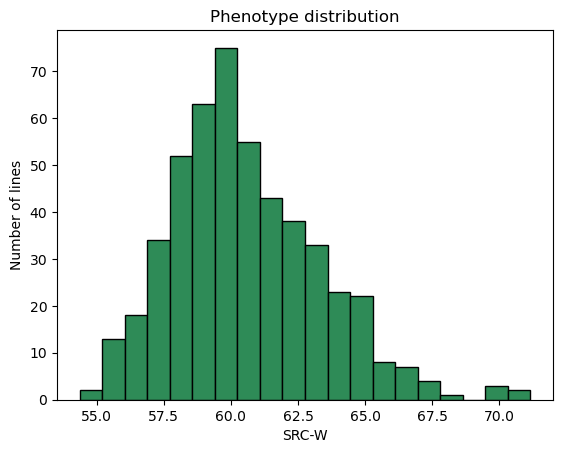

In [4]:
plt.hist(pheno, bins=20, color="seagreen", edgecolor="black")
plt.xlabel(TRAIT_COL); plt.ylabel("Number of lines"); plt.title("Phenotype distribution")
plt.show()

## 4. Association analysis
For each SNP, fit a simple linear regression: `Trait ~ genotype`.
The **slope** is the effect size and the **p-value** tells whether the SNP is associated with the trait.

In [5]:
results = []
for snp in geno.columns:
    res = stats.linregress(geno[snp], pheno)
    results.append((snp, res.slope, res.pvalue))

gwas = pd.DataFrame(results, columns=["SNP", "Effect", "P"]).dropna()
gwas = snp_info.merge(gwas, on="SNP")
gwas["P"] = gwas["P"].clip(lower=1e-300)
gwas["-log10P"] = -np.log10(gwas["P"])
gwas.sort_values("P").head(10)

,SNP,CHR,POS,Effect,P,-log10P
23,rs24,1,1024,0.594847,0.000017,4.764503
22641,rs22972,21,210438,0.664236,0.000022,4.658040
9938,rs10144,8,801397,-0.535550,0.000045,4.345196
20,rs21,1,1021,0.558880,0.000049,4.307568
49,rs51,1,1051,0.592802,0.000054,4.269521
60,rs62,1,1062,0.567480,0.000062,4.207795
5732,rs5828,5,50986,0.773245,0.000100,4.000281
1271,rs1307,2,20151,-0.688838,0.000146,3.834208
4086,rs4160,4,40609,0.479758,0.000161,3.793587
25,rs26,1,1026,0.525185,0.000166,3.779867


## 5. Multiple-testing correction
Thousands of SNPs are tested, so we use a **Bonferroni threshold** = 0.05 / number of SNPs.
(With real data it is common that no SNP passes this strict line - then discuss the top SNPs as *suggestive*.)

In [6]:
threshold = 0.05 / len(gwas)
gwas["Significant"] = gwas["P"] < threshold

print(f"SNPs tested: {len(gwas)}")
print(f"Bonferroni threshold: {threshold:.2e}  (-log10 = {-np.log10(threshold):.2f})")
print("Significant SNPs:", int(gwas["Significant"].sum()))
gwas[gwas["Significant"]].sort_values("P")

SNPs tested: 22797
Bonferroni threshold: 2.19e-06  (-log10 = 5.66)
Significant SNPs: 0


,SNP,CHR,POS,Effect,P,-log10P,Significant


## 6. Manhattan plot

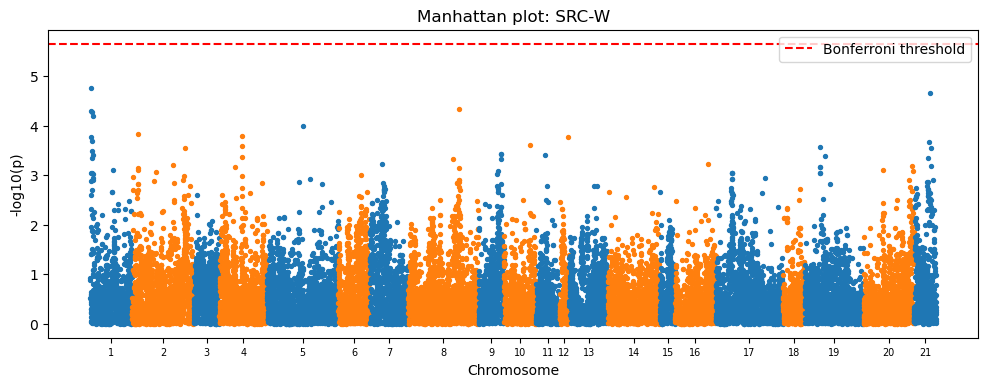

In [7]:
# order SNPs by chromosome (order of appearance in the file) and position
gwas["CHR"] = pd.Categorical(gwas["CHR"], categories=list(dict.fromkeys(gwas["CHR"])))
gwas = gwas.sort_values(["CHR", "POS"]).reset_index(drop=True)
gwas["X"] = np.arange(len(gwas))

plt.figure(figsize=(12, 4))
colors = ["#1f77b4", "#ff7f0e"]
ticks, labels = [], []

for i, (chrom, d) in enumerate(gwas.groupby("CHR", observed=True)):
    plt.scatter(d["X"], d["-log10P"], s=8, color=colors[i % 2])
    ticks.append(d["X"].mean()); labels.append(chrom)

plt.axhline(-np.log10(threshold), color="red", linestyle="--", label="Bonferroni threshold")
plt.xticks(ticks, labels, fontsize=7)
plt.xlabel("Chromosome"); plt.ylabel("-log10(p)")
plt.title(f"Manhattan plot: {TRAIT_COL}"); plt.legend()
plt.show()

## 7. QQ plot
Points should follow the diagonal except at the tail (true associations).

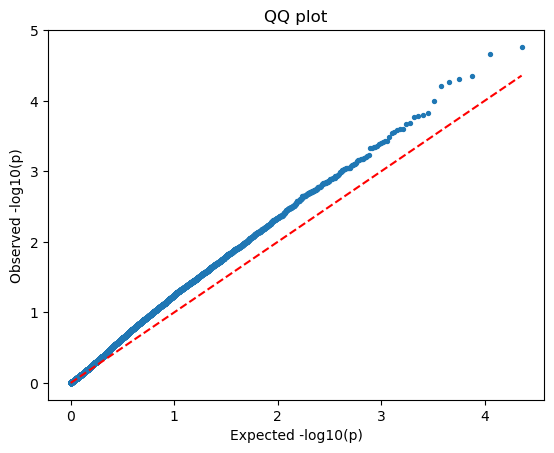

In [8]:
p = np.sort(gwas["P"].values)
expected = -np.log10(np.arange(1, len(p) + 1) / (len(p) + 1))
observed = -np.log10(p)

plt.scatter(expected, observed, s=8)
plt.plot([0, expected.max()], [0, expected.max()], "r--")
plt.xlabel("Expected -log10(p)"); plt.ylabel("Observed -log10(p)")
plt.title("QQ plot")
plt.show()

## 8. Effect of top marker on the trait

Top SNP: rs24  chr1:1024  effect=0.595  p=1.72e-05


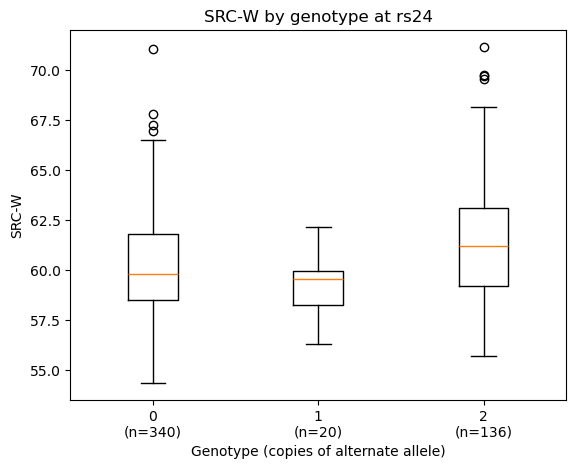

In [9]:
top = gwas.sort_values("P").iloc[0]
print(f"Top SNP: {top['SNP']}  chr{top['CHR']}:{int(top['POS'])}  effect={top['Effect']:.3f}  p={top['P']:.2e}")

snp_geno = geno[top["SNP"]].round().astype(int)
groups = [(g, pheno[snp_geno == g]) for g in sorted(snp_geno.unique())]   # only genotypes that exist

fig, ax = plt.subplots()
ax.boxplot([v for _, v in groups])
ax.set_xticklabels([f"{g}\n(n={len(v)})" for g, v in groups])
ax.set_xlabel("Genotype (copies of alternate allele)"); ax.set_ylabel(TRAIT_COL)
ax.set_title(f"{TRAIT_COL} by genotype at {top['SNP']}")
plt.show()

## 9. (Optional) Binary trait: high vs low
The dataset has no resistant/susceptible column, so lines are split at the **median** of the trait (1 = above median, 0 = below).
Each SNP is tested with a chi-square test. This loop can take a minute for many SNPs.

In [ ]:
binary = (pheno > pheno.median()).astype(int)

chi_results = []
for snp in geno.columns:
    table = pd.crosstab(geno[snp].round(), binary)
    if table.shape[0] < 2:
        continue
    chi2, pval, _, _ = stats.chi2_contingency(table)
    chi_results.append((snp, pval))

chi = pd.DataFrame(chi_results, columns=["SNP", "P"]).sort_values("P")
chi.head(5)

## 10. Conclusion
- Mention the trait analysed and the number of SNPs after QC.
- List the top SNPs (chromosome, position, effect, p-value) and whether they pass the Bonferroni line.
- Explain that such markers can be used for **marker-assisted selection** in crop improvement; GWAS shows association, which needs validation.